### Study signal

You can filter what counts as a peak using:

    height= → minimum amplitude

    distance= → minimum distance between peaks (in samples)

    prominence= → how much a peak stands out

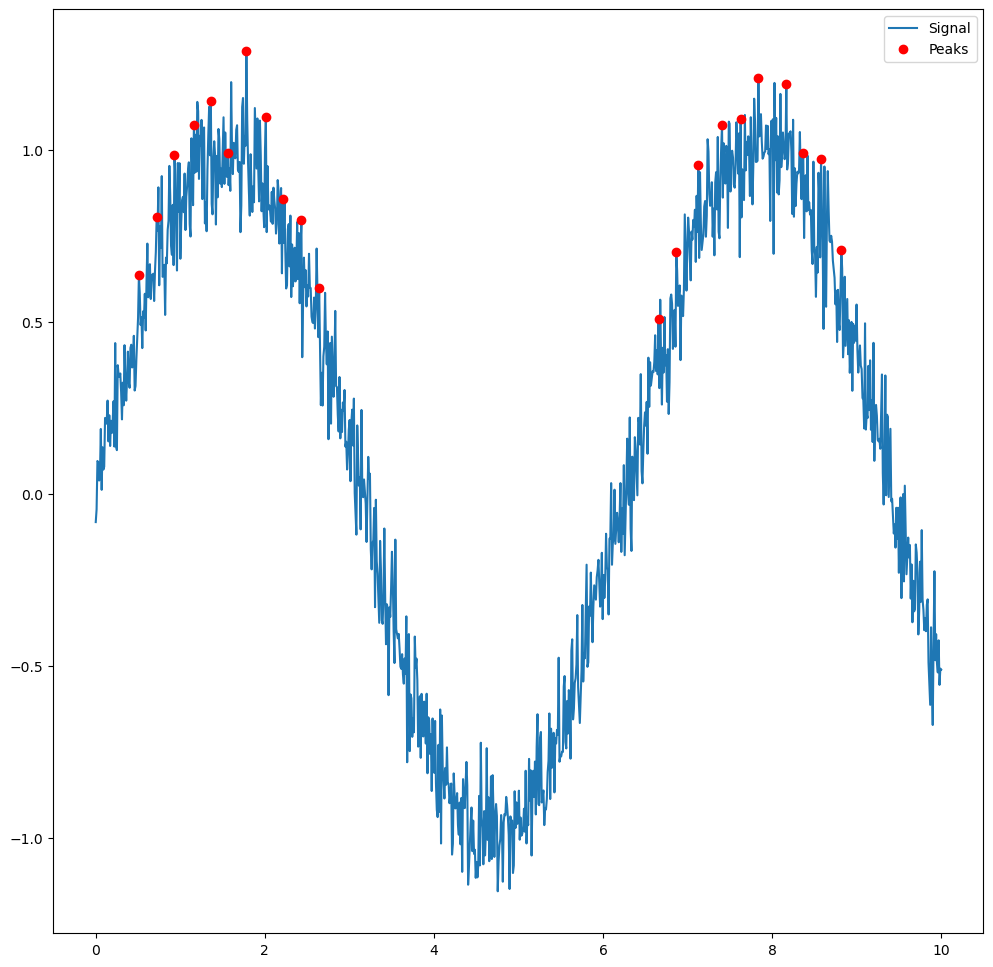

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Let's say you already have x (timestamps) and y (amplitudes)

# Example data:
x = np.linspace(0, 10, 1000)
y = np.sin(x) + 0.1 * np.random.randn(1000)

# Find indices of local maxima
#peak_indices = find_peaks(y)[0]
peak_indices = find_peaks(y, height=0.5, distance=20)[0]

# Get the corresponding timestamp and amplitude values
peak_times = x[peak_indices]
peak_amps = y[peak_indices]

# Optional: plot it
plt.figure(figsize=(12,12))
plt.plot(x, y, label='Signal')
plt.plot(peak_times, peak_amps, 'ro', label='Peaks')
plt.legend()
plt.show()


### Fit to sin (not-damped)???

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Your data
# x = np.array([...])  # timestamps
# y = np.array([...])  # amplitudes

# Model: a sine function
def model(x, A, omega, phi, offset):
    return A * np.sin(omega * x + phi) + offset

# Initial guess: [amplitude, frequency, phase, offset]
guess = [np.std(y), 2*np.pi/(x[-1] - x[0]), 0, np.mean(y)]

params, _ = curve_fit(model, x, y, p0=guess)

A, omega, phi, offset = params

print(f"Fitted parameters:\nAmplitude = {A}\nOmega = {omega}\nPhase = {phi}\nOffset = {offset}")


Fitted parameters:
Amplitude = 0.9971794636467337
Omega = 0.999197523869743
Phase = 0.012575036238394023
Offset = 0.0058503469050102345


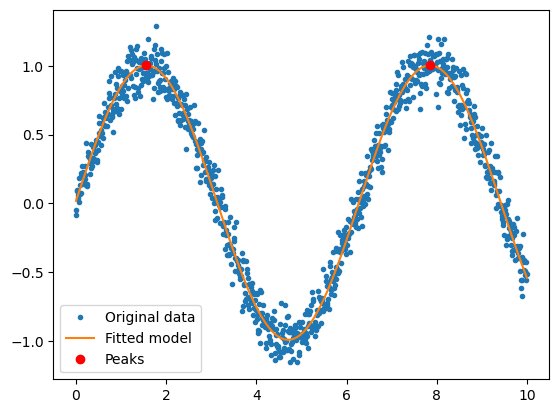

In [8]:
# Generate time values for many cycles
n_values = np.arange(-10, 100)  # adjust range depending on your data
x_peaks = (np.pi/2 - phi + 2 * np.pi * n_values) / omega

# Filter to keep only the peaks within your x range
x_peaks = x_peaks[(x_peaks >= x.min()) & (x_peaks <= x.max())]

# Compute amplitudes at those peaks
y_peaks = model(x_peaks, *params)

# Plot
plt.plot(x, y, '.', label='Original data')
x_smooth = np.linspace(x.min(), x.max(), 1000)
plt.plot(x_smooth, model(x_smooth, *params), label='Fitted model')
plt.plot(x_peaks, y_peaks, 'ro', label='Peaks')
plt.legend()
plt.show()


### Fit damped obscillator

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

**Get data**

In [10]:
# Get data

# x = np.array([...])
# y = np.array([...])

In [11]:
# === 1. Generate synthetic damped oscillator data === TO TEST IT WORKS

np.random.seed(42)

# Time values
x = np.linspace(0, 10, 300)

# True parameters
A_true = 2.0
lambda_true = 0.2
omega_true = 2 * np.pi * 1.0  # 1 Hz
phi_true = 0.3
offset_true = 0.5

# True signal
def true_func(x):
    return A_true * np.exp(-lambda_true * x) * np.sin(omega_true * x + phi_true) + offset_true

# Noisy measurements
noise = 0.2 * np.random.randn(len(x))
y = true_func(x) + noise

**Fit**

In [12]:
# Define the damped sine function

def damped_oscillator(x, A, lambda_, omega, phi, offset):
    return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

In [13]:
# Initial guesses — tweak if needed

A_guess = (np.max(y) - np.min(y)) / 2
lambda_guess = 0.1
omega_guess = 2 * np.pi / (x[-1] - x[0])  # rough frequency guess
phi_guess = 0
offset_guess = np.mean(y)

p0 = [A_guess, lambda_guess, omega_guess, phi_guess, offset_guess]

In [14]:
# Fit
params, _ = curve_fit(damped_oscillator, x, y, p0=p0)
A, lambda_, omega, phi, offset = params


In [15]:
# Output

print("Fitted parameters:")
print(f"  Amplitude: {A}")
print(f"  Damping: {lambda_}")
print(f"  Omega: {omega}")
print(f"  Phase: {phi}")
print(f"  Offset: {offset}")

Fitted parameters:
  Amplitude: -2.0329359813671832
  Damping: 0.20064344646274992
  Omega: 6.282951484034321
  Phase: -2.8097412154134718
  Offset: 0.49854584311791367


**Find peaks**

In [16]:
# Evaluate the fitted function on a fine grid
x_dense = np.linspace(x.min(), x.max(), 5000)
y_fitted = damped_oscillator(x_dense, *params)

# Find peaks in the smooth curve
peak_indices, _ = find_peaks(y_fitted)
x_peaks = x_dense[peak_indices]
y_peaks = y_fitted[peak_indices]

In [17]:
print("Detected peak times:", x_peaks)
print("Detected peak amplitudes:", y_peaks)

Detected peak times: [0.19203841 1.19223845 2.19243849 3.19263853 4.19283857 5.19303861
 6.19323865 7.19143829 8.19163833 9.19183837]
Detected peak amplitudes: [2.45361501 2.09817944 1.80736141 1.56941382 1.37472508 1.2154309
 1.08509665 0.97846006 0.89121285 0.81982662]


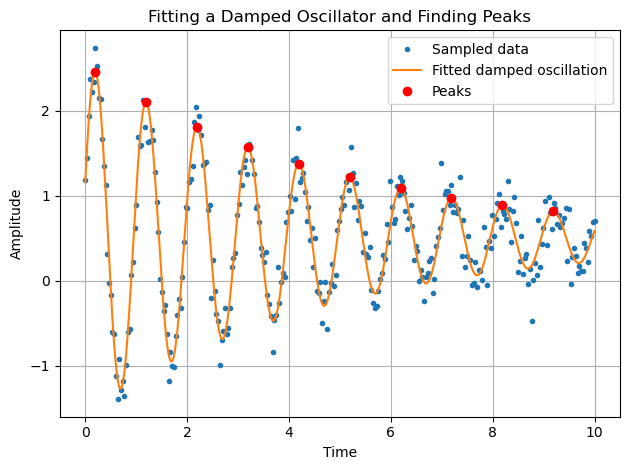

In [18]:
# === 5. Plot everything ===

plt.plot(x, y, '.', label='Sampled data')
plt.plot(x_dense, y_fitted, label='Fitted damped oscillation')
plt.plot(x_peaks, y_peaks, 'ro', label='Peaks')
plt.title('Fitting a Damped Oscillator and Finding Peaks')

plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Working example

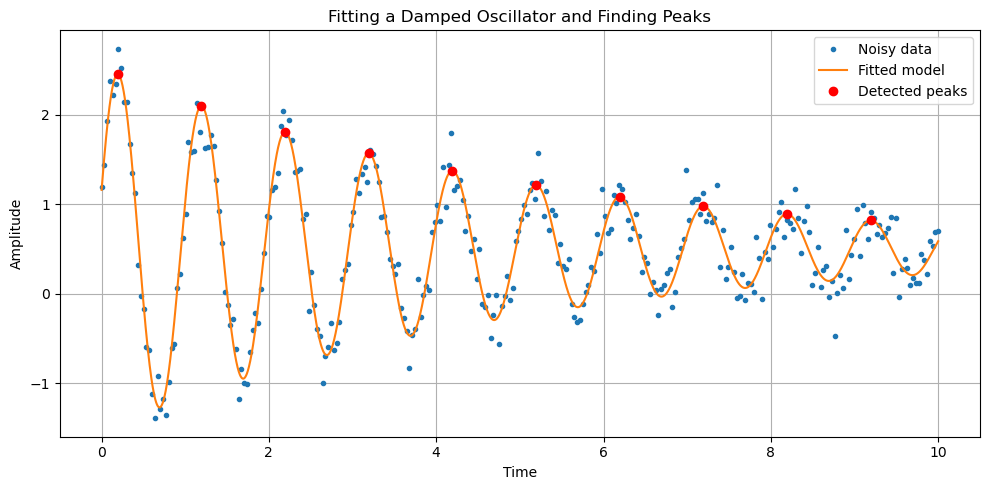

Detected peak times: [0.19203841 1.19223845 2.19243849 3.19263853 4.19283857 5.19303861
 6.19323865 7.19143829 8.19163833 9.19183837]
Detected peak amplitudes: [2.45361698 2.09818024 1.80736141 1.56941328 1.37472419 1.2154298
 1.08509546 0.97845883 0.89121164 0.81982547]


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# === 1. Generate synthetic damped oscillator data ===
np.random.seed(42)

# Time values
x = np.linspace(0, 10, 300)

# True parameters
A_true = 2.0
lambda_true = 0.2
omega_true = 2 * np.pi * 1.0  # 1 Hz
phi_true = 0.3
offset_true = 0.5

# True signal
def true_func(x):
    return A_true * np.exp(-lambda_true * x) * np.sin(omega_true * x + phi_true) + offset_true

# Noisy measurements
noise = 0.2 * np.random.randn(len(x))
y = true_func(x) + noise

# === 2. Define model for fitting ===
def damped_oscillator(x, A, lambda_, omega, phi, offset):
    return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

# === 3. Fit the model ===
guess = [1.0, 0.1, 2*np.pi, 0.0, 0.0]
params, _ = curve_fit(damped_oscillator, x, y, p0=guess)
A, lambda_, omega, phi, offset = params

# === 4. Evaluate fitted model on dense grid and find peaks ===
x_dense = np.linspace(x.min(), x.max(), 5000)
y_fit = damped_oscillator(x_dense, *params)

peak_indices, _ = find_peaks(y_fit)
x_peaks = x_dense[peak_indices]
y_peaks = y_fit[peak_indices]

# === 5. Plot everything ===
plt.figure(figsize=(10,5))
plt.plot(x, y, '.', label='Noisy data')
plt.plot(x_dense, y_fit, label='Fitted model')
plt.plot(x_peaks, y_peaks, 'ro', label='Detected peaks')
plt.title('Fitting a Damped Oscillator and Finding Peaks')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Print peak info
print("Detected peak times:", x_peaks)
print("Detected peak amplitudes:", y_peaks)
